# Building a Movie Recommendation System
## Milestone 1: Ratings as a Matrix
*MATH 344L Applied Linear Algebra Lab*

**Goal** Represent movie ratings as a matrix, explore the MovieLens 100K data set, and explain why
a recommender system is a linear algebra problem. The missing entries of the ratings matrix are
exactly the ratings we want to predict.

## Setup
Every notebook starts with the same three libraries. NumPy handles arrays and linear algebra,
pandas handles labeled tables, and Matplotlib handles plots.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Part A: A small ratings matrix

We start with a toy example with six people and six movies. The two lists below are only *labels*
for the rows and columns. They are not the matrix itself.

In [2]:
movies = ["Action 1", "Action 2", "Action 3",
          "Romance 1", "Romance 2", "Romance 3"]
users = ["Ana", "Ben", "Cal", "Dee", "Eve", "Fay"]

Now the ratings. Each row is a person, each column is a movie, and each entry is a 1–5 star
rating. `np.nan` marks a movie that the person has not rated.

In [3]:
toy = np.array([
    [5, 4, 5, 1, np.nan, 2],       # Ana
    [4, np.nan, 5, 2, 1, 1],       # Ben
    [5, 5, np.nan, 1, 2, np.nan],  # Cal
    [1, 2, 1, 5, 4, np.nan],       # Dee
    [np.nan, 1, 2, 4, 5, 5],       # Eve
    [2, 1, np.nan, 5, np.nan, 4],  # Fay
])
toy.shape

(6, 6)

`toy` is a $6 \times 6$ NumPy array. A pandas `DataFrame` shows the same numbers with the user
names as row labels and the movie names as column labels, which makes it much easier to read.

In [4]:
toy_table = pd.DataFrame(toy, index=users, columns=movies)
toy_table

,Action 1,Action 2,Action 3,Romance 1,Romance 2,Romance 3
Ana,5.0,4.0,5.0,1.0,NaN,2.0
Ben,4.0,NaN,5.0,2.0,1.0,1.0
Cal,5.0,5.0,NaN,1.0,2.0,NaN
Dee,1.0,2.0,1.0,5.0,4.0,NaN
Eve,NaN,1.0,2.0,4.0,5.0,5.0
Fay,2.0,1.0,NaN,5.0,NaN,4.0


To count the missing entries, `np.isnan(toy)` builds a matrix of `True`/`False` values that is
`True` exactly where a rating is missing. Summing it counts the `True`s,
and `toy.size` is the total number of entries, $6 \cdot 6 = 36$.

In [5]:
missing = np.isnan(toy).sum()
print("Missing entries:", missing, "out of", toy.size)

Missing entries: 8 out of 36


### Making predictions by hand
Before using any algorithm, we guess the missing ratings ourselves. Ana, Ben, and Cal like action
movies and dislike romance, while Dee, Eve, and Fay show the opposite pattern. So a natural guess for a
missing rating is to *look at what the people with similar taste gave that movie.*

The cell below automates exactly that idea, as a check on our guesses. For each missing entry, it
averages the ratings that the other members of the same "taste group" gave the same movie.

In [6]:
action_fans = ["Ana", "Ben", "Cal"]
romance_fans = ["Dee", "Eve", "Fay"]

rows = []
for user in users:
    group = action_fans if user in action_fans else romance_fans
    for movie in movies:
        if np.isnan(toy_table.loc[user, movie]):
            similar = toy_table.loc[group, movie].drop(user)   # other people in the same group
            rows.append({"user": user, "movie": movie,
                         "similar users' ratings": similar.dropna().tolist(),
                         "group average": round(similar.mean(), 2)})

group_guess = pd.DataFrame(rows)
group_guess

,user,movie,similar users' ratings,group average
0,Ana,Romance 2,"[1.0, 2.0]",1.5
1,Ben,Action 2,"[4.0, 5.0]",4.5
2,Cal,Action 3,"[5.0, 5.0]",5.0
3,Cal,Romance 3,"[2.0, 1.0]",1.5
4,Dee,Romance 3,"[5.0, 4.0]",4.5
5,Eve,Action 1,"[1.0, 2.0]",1.5
6,Fay,Action 3,"[1.0, 2.0]",1.5
7,Fay,Romance 2,"[4.0, 5.0]",4.5


Below are our final predictions, filled into the matrix.

In [7]:
predictions = {
    ("Ana", "Romance 2"): 1,
    ("Ben", "Action 2"):  5,
    ("Cal", "Action 3"):  5,
    ("Cal", "Romance 3"): 1,
    ("Dee", "Romance 3"): 5,
    ("Eve", "Action 1"):  1,
    ("Fay", "Action 3"):  1,
    ("Fay", "Romance 2"): 5,
}

filled = toy_table.copy()
for (user, movie), stars in predictions.items():
    filled.loc[user, movie] = stars
filled

,Action 1,Action 2,Action 3,Romance 1,Romance 2,Romance 3
Ana,5.0,4.0,5.0,1.0,1.0,2.0
Ben,4.0,5.0,5.0,2.0,1.0,1.0
Cal,5.0,5.0,5.0,1.0,2.0,1.0
Dee,1.0,2.0,1.0,5.0,4.0,5.0
Eve,1.0,1.0,2.0,4.0,5.0,5.0
Fay,2.0,1.0,1.0,5.0,5.0,4.0


---
## Part B: The MovieLens data

MovieLens 100K contains 100,000 real movie ratings. The cell below downloads and unzips it into
the notebook's temporary working space, but only if it is not already there.

In [8]:
import os
import urllib.request
import zipfile

if not os.path.exists("ml-100k"):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip"
    )
    zipfile.ZipFile("ml-100k.zip").extractall()

The ratings live in `ml-100k/u.data`. It is a text file whose columns are separated by tabs,
so we pass `sep="\t"`. The file has no header line, so we supply the column names ourselves, as listed below.

| Column | Meaning |
|---|---|
| `user` | ID number of the person who gave the rating |
| `item` | ID number of the movie |
| `rating` | number of stars, 1 to 5 |
| `time` | timestamp of when the rating was submitted |

Each row of this table is one rating. `ratings.head()` just displays the first five rows.

In [9]:
ratings = pd.read_csv(
    "ml-100k/u.data",
    sep="\t",
    names=["user", "item", "rating", "time"]
)
ratings.head()

,user,item,rating,time
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


For example, the first row says user 196 gave movie 242 three stars. Next we count the rows
(`len`) and the number of *distinct* users and movies (`.nunique()`).

In [10]:
print("Number of ratings:", len(ratings))
print("Number of users:", ratings["user"].nunique())
print("Number of movies:", ratings["item"].nunique())

Number of ratings: 100000
Number of users: 943
Number of movies: 1682


So there are 100,000 ratings from 943 users on 1,682 movies.

How are the stars distributed? `value_counts()` counts how often each rating appears and
`sort_index()` puts them in the order 1, 2, 3, 4, 5. `mean()` gives the ordinary average.

In [11]:
star_counts = ratings["rating"].value_counts().sort_index()
star_counts

rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64

In [12]:
average_rating = ratings["rating"].mean()
print("Average rating:", round(average_rating, 3))

Average rating: 3.53


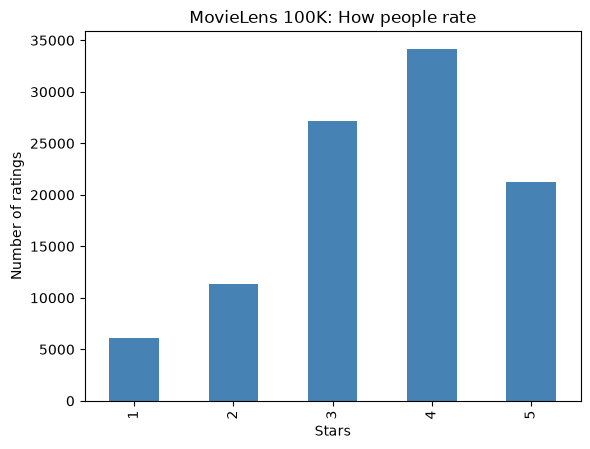

In [13]:
star_counts.plot(kind="bar", color="steelblue")
plt.xlabel("Stars")
plt.ylabel("Number of ratings")
plt.title("MovieLens 100K: How people rate")
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/star_counts.png", dpi=150, bbox_inches="tight")
plt.show()

Ratings of 3 and 4 stars are the most common and 1 star is the rarest, and the average is about
3.53, which is above the midpoint of 3. This makes sense because people mostly choose to watch
movies they expect to enjoy, so the ratings skew positive.

---
## Part C: Building the user-by-movie matrix

The raw table has one row per rating. For linear algebra we want a matrix $R$ with one row
per user and one column per movie, so that $R_{ij}$ is the rating user $i$ gave movie $j$.
A pivot table does that reorganization. `index="user"` makes the rows, `columns="item"` makes the
columns, and `values="rating"` fills in the entries. If a user never rated a movie, the entry is `NaN`.

In [14]:
R = ratings.pivot_table(
    index="user",
    columns="item",
    values="rating"
)
print("Matrix shape:", R.shape)

Matrix shape: (943, 1682)


$R$ is $943 \times 1682$. How much of it is empty? `R.isna()` marks missing entries with `True`.
After converting to a NumPy array, `.mean()` treats `True` as 1 and `False` as 0, so it returns the
fraction of entries that are missing.

In [15]:
fraction_missing = R.isna().to_numpy().mean()
print("Fraction missing:", round(fraction_missing, 4))

Fraction missing: 0.937


About 93.7% of the matrix is missing. Each user has rated only a tiny fraction of the movies.
How active are the users? `groupby("user")` collects each person's ratings, and `.size()` counts them.

In [16]:
per_user = ratings.groupby("user").size()

print("Least active user:", per_user.min())
print("Median user:", int(per_user.median()))
print("Most active user:", per_user.max())

Least active user: 20
Median user: 65
Most active user: 737


Every user rated at least 20 movies, a typical user rated 65, and the most active user rated 737.

Why not take the SVD now? `np.linalg.svd` needs every entry of the matrix to be an actual
number. Because $R$ is full of `NaN`s, it can't be used directly. Filling in those missing entries
*is* the recommendation problem, and we will attack it with low-rank ideas in later milestones.

---
## Part D: Which movies are rated most?

Movie titles are in `ml-100k/u.item`. That file separates columns with vertical bars (`sep="|"`),
and some titles contain accented characters, so we need `encoding="latin-1"`. We keep only the first
two columns, the movie ID and its title.

In [17]:
titles = pd.read_csv(
    "ml-100k/u.item",
    sep="|",
    encoding="latin-1",
    header=None,
    usecols=[0, 1],
    names=["item", "title"]
)
titles.head()

,item,title
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)


Now we group the ratings by movie and compute, for each movie, how many ratings it got (`count`)
and its average rating (`mean`). `join` attaches the title to each movie ID. Sorting by `count`
from largest to smallest and taking the first five rows gives the most-rated movies.

In [18]:
stats = ratings.groupby("item")["rating"].agg(["count", "mean"])
stats = stats.join(titles.set_index("item"))

top_five = stats.sort_values("count", ascending=False).head(5)
top_five.round(2)

,count,mean,title
item,,,
50,583,4.36,Star Wars (1977)
258,509,3.80,Contact (1997)
100,508,4.16,Fargo (1996)
181,507,4.01,Return of the Jedi (1983)
294,485,3.16,Liar Liar (1997)


*Star Wars (1977)* is the most-rated movie in the data set (583 ratings, average 4.36). Being
rated often is not the same as being rated highly, though. *Liar Liar (1997)* is in the top five by
count but averages only about 3.16 stars.

---
## Why a low-rank model is plausible

People don't rate each movie with an independent, random judgment. Their ratings are driven by a
fairly small number of hidden preferences, such as action vs. romance, comedy vs. drama, old vs. new,
or blockbuster vs. indie. Each user has some amount of each preference, and each movie has some amount
of each feature. A rating is then roughly "how much the user's tastes line up with the movie's features".

If only $k$ such factors matter, every row of $R$ is (approximately) a combination of just $k$
"taste profiles", which means $R$ is approximately a rank-$k$ matrix with $k$ much smaller than
943 or 1682. The toy matrix shows this in miniature. With the predictions filled in, its rows come in
just two patterns (action fans and romance fans), so it is close to rank 2.

In [19]:
singular_values = np.linalg.svd(filled.to_numpy(), compute_uv=False)
print("Singular values of the filled-in toy matrix:", singular_values.round(2))

Singular values of the filled-in toy matrix: [18.18 10.17  1.76  1.53  1.1   0.68]


Two singular values are large and the remaining four are small by comparison, confirming that
two hidden factors explain most of the toy ratings. (This SVD works only because we filled every
missing entry first. That is exactly the obstacle described in Part C.)

---
## Exercises

### Exercise 1: The eight missing toy ratings

| User | Missing movie | Prediction |
|---|---|---|
| Ana | Romance 2 | 1 |
| Ben | Action 2 | 5 |
| Cal | Action 3 | 5 |
| Cal | Romance 3 | 1 |
| Dee | Romance 3 | 5 |
| Eve | Action 1 | 1 |
| Fay | Action 3 | 1 |
| Fay | Romance 2 | 5 |

Justification (Ana, Romance 2). Ana's ratings look like Ben's and Cal's, high on action
(5, 4, 5) and low on romance (1, 2). Ben and Cal gave Romance 2 ratings of 1 and 2, and Ana herself
gave the other romance movies a 1 and a 2. So she most likely dislikes Romance 2 too, giving 1 star.

Justification (Fay, Action 3). Fay is a romance fan (5 and 4 on romance, 2 and 1 on action),
like Dee and Eve. Dee and Eve gave Action 3 ratings of 1 and 2. Looking at similar *movies*, Fay gave
the other action films a 2 and a 1. Both views point to a low rating of 1 star.

The `group_guess` table in Part A gives the same answers numerically (e.g. 1.5 for Ana/Romance 2 and
1.5 for Fay/Action 3). We rounded toward the extreme because each person's own ratings on similar
movies are just as strong.

### Exercise 2: A seventh user

Gus likes action and dislikes romance. He has rated four movies and is missing two, as shown below.

In [20]:
gus = [5, np.nan, 4, 1, np.nan, 2]   # Action 2 and Romance 2 missing

toy7 = np.vstack([toy, gus])
toy7_table = pd.DataFrame(toy7, index=users + ["Gus"], columns=movies)
toy7_table

,Action 1,Action 2,Action 3,Romance 1,Romance 2,Romance 3
Ana,5.0,4.0,5.0,1.0,NaN,2.0
Ben,4.0,NaN,5.0,2.0,1.0,1.0
Cal,5.0,5.0,NaN,1.0,2.0,NaN
Dee,1.0,2.0,1.0,5.0,4.0,NaN
Eve,NaN,1.0,2.0,4.0,5.0,5.0
Fay,2.0,1.0,NaN,5.0,NaN,4.0
Gus,5.0,NaN,4.0,1.0,NaN,2.0


Predictions for Gus.
- *Action 2*. The other action fans gave it 4 (Ana) and 5 (Cal), and Gus rated the other action
  movies 5 and 4. The prediction is 4–5 stars, say 5.
- *Romance 2*. The action fans gave it 1 (Ben) and 2 (Cal), and Gus rated the other romance movies
  1 and 2. The prediction is 1 star.

### Exercise 3: What does `np.isnan(toy).sum()` compute?

`np.isnan(toy)` makes a $6 \times 6$ matrix of booleans that is `True` wherever a rating is
missing. `.sum()` adds them up, counting `True` as 1, so the expression gives the number of missing
ratings, 8. A different line that gives the fraction missing is to take the mean instead of the
sum (the same trick as in Part C), as in the cell below.

In [21]:
print("Fraction missing in toy:", np.isnan(toy).mean())        # 8/36
print("Same thing another way:  ", np.isnan(toy).sum() / toy.size)

Fraction missing in toy: 0.2222222222222222
Same thing another way:   0.2222222222222222


### Exercise 4: The least common star rating

In [22]:
least_common = star_counts.idxmin()
print("Least common rating:", least_common, "stars, occurring", star_counts.min(), "times")

Least common rating: 1 stars, occurring 6110 times


The least common rating is 1 star, which occurs 6,110 times.

### Exercise 5: Average rating per user

In [23]:
user_stats = ratings.groupby("user")["rating"].agg(["mean", "count"])
user_stats.sort_values("mean", ascending=False).head(5).round(3)

,mean,count
user,,
849,4.870,23
688,4.833,24
507,4.724,58
628,4.704,27
928,4.688,32


In [24]:
top_user = user_stats["mean"].idxmax()
print("User with highest average:", top_user,
      "| average:", round(user_stats.loc[top_user, "mean"], 3),
      "| number of ratings:", user_stats.loc[top_user, "count"])
print("Median number of ratings per user:", user_stats["count"].median())

User with highest average: 849 | average: 4.87 | number of ratings: 23
Median number of ratings per user: 65.0


User 849 has the highest average rating, about 4.87 stars. We should be cautious about
calling them the "most positive" user, for a few reasons.
- They rated only 23 movies (the median user rated 65), so the average rests on a small sample
  and could change a lot with a few more ratings.
- People choose what to watch. User 849 may simply have watched only highly regarded movies that
  almost everyone likes, rather than being unusually generous.
- An average says nothing about how they rate *relative to other people* on the same movies. To
  measure positivity fairly, we'd compare each of their ratings to that movie's average rating.

### Exercise 6: `ratings` vs. `R`

- `ratings` is the raw data in "long" format, a $100{,}000 \times 4$ table where one row is one
  rating event. It records who (user), what (item), how many stars (rating), and when (time).
- `R` is the same information reorganized into a $943 \times 1682$ matrix where one row is one
  user, containing that user's ratings for *every* movie (mostly `NaN`), and one column is one movie.

`ratings` only stores ratings that exist, so it has no missing values. `R` has a slot for every
user and movie pair, which is what makes it a matrix we can do linear algebra with. It also makes the
missing ratings visible as `NaN` entries.

### Exercise 7: If $R$ had no missing entries

Why the SVD would be possible. Every matrix of real numbers, of any shape, has a singular value
decomposition $R = U \Sigma V^T$. `np.linalg.svd` just needs actual numbers in every entry. With no
`NaN`s, it would run on the $943 \times 1682$ matrix without a problem.

Why it still might not solve the recommendation problem.
- If every rating were known, there would be nothing left to predict. Recommending would just mean
  picking each user's highest-rated unseen movie, but every movie would already be "seen". The real
  problem is predicting *unknown* ratings, which we would have to fill in somehow before the SVD.
- Even with a full matrix, the SVD by itself is just a factorization, and it reproduces $R$ exactly. The
  useful step is choosing a rank $k$ and keeping only the top $k$ singular values to capture the
  main patterns and discard noise, and the SVD doesn't tell us what $k$ should be.
- The singular vectors are abstract. They don't directly say "this is the action factor", so
  interpreting them and turning them into recommendations takes additional work.

### Exercise 8: Three possible hidden factors

| Factor | High value for a user | High value for a movie |
|---|---|---|
| Action / excitement | The user enjoys fast-paced action, fights, and explosions | The movie is full of action sequences (e.g. *Star Wars*) |
| Romance / emotion | The user enjoys love stories and emotional drama | The movie centers on a relationship or love story |
| Classic / older films | The user enjoys and rates older films highly | The movie is an older or classic film (e.g. from before 1970) |

A rating is then predicted from how well the user's factor values match the movie's. A user with a
high action value watching a high-action movie should give a high rating.